# 01 — Acquisition des données de l'accéléromètre

**Projet 5 — Analyse des mouvements avec un accéléromètre** (MPU-6050 + ESP32-C3)

Ce notebook enregistre les données envoyées par l'ESP32-C3 sur le port série et les sauvegarde en **CSV brut** dans `data/raw/`.

**Chaîne d'acquisition :** MPU-6050 → (I²C, 400 kHz) → ESP32-C3 → (USB série) → ce notebook → `data/raw/<situation>_rep<n>.csv`

**Paramètres fixés dans le sketch `test_mpu/test_mpu.ino` :**
- Fréquence d'échantillonnage fixe : **Fe = 100 Hz** (Te = 10 ms)
- Plage de mesure : **±2 g** (16384 LSB/g, résolution ≈ 0,06 mg)
- Filtre passe-bas interne du capteur (DLPF) : **≈ 44 Hz**, anti-repliement (< Fe/2 = 50 Hz)

**Avant de lancer :**
1. Téléverser `test_mpu/test_mpu.ino` sur l'ESP32-C3 avec l'Arduino IDE, avec **Outils → USB CDC On Boot → Enabled** (sinon `Serial` sort sur les broches UART et non sur l'USB) et **Flash Mode → DIO**.
2. **Fermer le moniteur série de l'Arduino IDE** : un port série ne peut être ouvert que par un seul programme à la fois.
3. Fixer solidement le capteur (consigne de sécurité du sujet).

> Règle du projet : les fichiers bruts ne sont **jamais** écrasés. Si un fichier existe déjà, l'acquisition est refusée.

## 0. Installation (une seule fois)
`pyserial` permet à Python de lire le port série.

In [1]:
%pip install pyserial

  Obtaining dependency information for pyserial from https://files.pythonhosted.org/packages/07/bc/587a445451b253b285629263eb51c2d8e9bcea4fc97826266d186f96f558/pyserial-3.5-py2.py3-none-any.whl.metadata
   ---------------------------------------- 0.0/90.6 kB ? eta -:--:--
   ---------------------------------------- 0.0/90.6 kB ? eta -:--:--
   ---- ----------------------------------- 10.2/90.6 kB ? eta -:--:--
   ---- ----------------------------------- 10.2/90.6 kB ? eta -:--:--
   ---- ----------------------------------- 10.2/90.6 kB ? eta -:--:--
   ------------- -------------------------- 30.7/90.6 kB 187.9 kB/s eta 0:00:01
   ------------------ --------------------- 41.0/90.6 kB 151.3 kB/s eta 0:00:01
   ------------------ --------------------- 41.0/90.6 kB 151.3 kB/s eta 0:00:01
   --------------------------- ------------ 61.4/90.6 kB 193.2 kB/s eta 0:00:01
   ---------------------------------------- 90.6/90.6 kB 257.5 kB/s eta 0:00:00
Note: you may need to restart the kernel to 


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports

In [1]:
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import serial
from serial.tools import list_ports

## 2. Trouver le port série de l'ESP32-C3
Repérer la ligne qui correspond à la carte (souvent `USB JTAG/serial debug unit` ou `USB-SERIAL`) et noter son nom (`COM3`, `COM5`…).

In [2]:
for p in list_ports.comports():
    print(f"{p.device:8s}  {p.description}")

COM5      USB Serial Device (COM5)


## 3. Paramètres

In [41]:
PORT    = "COM5"      # port de l'ESP32-C3 (à adapter si la carte change de port)
BAUD    = 115200      # identique à Serial.begin() dans le sketch
FE_HZ   = 100         # fréquence d'échantillonnage du sketch (Hz)
DUREE_S = 15          # durée d'un enregistrement (s) — identique pour toutes les répétitions
DECOMPTE_S = 3        # décompte avant le début de l'enregistrement (s)

# Les 4 situations imposées par le sujet (consigne 23)
SITUATIONS  = ["immobile", "inclinaison", "rotation", "oscillations"]
REPETITIONS = [1, 2, 3]

# Guide affiché pendant l'enregistrement : {seconde écoulée : action à commencer}.
# Le temps écoulé (1, 2, ... 15 s) s'affiche dans tous les cas ; l'action seulement si elle
# est définie ici. Les instants de "inclinaison" reprennent ceux observés sur la répétition 1
# (pour que les répétitions 2 et 3 soient faites à l'identique).
GUIDE = {
    "inclinaison": {0: "immobile (X vers le haut)",
                    3: ">>> MONTER lentement (rotation autour de Y)",
                    8: ">>> MAINTENIR (≈ 90°, contre la butée)",
                    11: ">>> REDESCENDRE lentement",
                    14: ">>> IMMOBILE"},
    # Rotation contrôlée : demi-tour (180°) aller-retour autour de Y, vitesse constante
    # de 90° toutes les 2 s (45°/s). Chaque consigne indique où l'on doit ÊTRE à cet instant.
    "rotation":    {0: "immobile (même position de départ que l'inclinaison)",
                    2: ">>> TOURNER (aller, autour de Y)",
                    4: "    ... doit être à 1/4 de tour (90°)",
                    6: ">>> 1/2 tour (180°) atteint : MAINTENIR",
                    8: ">>> TOURNER (retour)",
                    10: "    ... doit être à 1/4 de tour (90°)",
                    12: ">>> position de départ : IMMOBILE"},
    # Petites oscillations : glissement va-et-vient de 3 cm sur la table, selon Y (axe du câble)
    "oscillations": {0: "immobile (bord avant de la plaque sur le trait 1)",
                     2: ">>> VA-ET-VIENT : suivre ALLER / RETOUR (trait 1 <-> trait 2)"},
}

# Métronome affiché pendant l'enregistrement : {situation : (début_s, fin_s)}.
# Une consigne ALLER / RETOUR toutes les 0,5 s = 1 aller-retour par seconde -> f = 1 Hz.
METRONOME = {"oscillations": (2, 15)}

DOSSIER_RAW = Path("../data/raw")
DOSSIER_RAW.mkdir(parents=True, exist_ok=True)
JOURNAL_ACQ = DOSSIER_RAW / "journal_acquisitions.csv"   # trace de chaque enregistrement

TE_US = 1_000_000 // FE_HZ   # période d'échantillonnage attendue (µs)
print(f"Fe = {FE_HZ} Hz, Te = {TE_US} µs, durée = {DUREE_S} s -> {DUREE_S * FE_HZ} échantillons par fichier")

Fe = 100 Hz, Te = 10000 µs, durée = 15 s -> 1500 échantillons par fichier


## 4. Fonctions d'acquisition et de contrôle

- `acquerir(situation, repetition)` : ouvre le port, ignore les lignes d'information (`#…`) et l'en-tête, fait un décompte, puis enregistre **exactement** `DUREE_S × FE_HZ` échantillons valides.
- `controler(df)` : vérifie la régularité de l'échantillonnage (Fe effective, écarts entre échantillons, échantillons manquants) et trace les 3 axes.

In [42]:
def lire_echantillon(ligne):
    """Convertit une ligne 't_us,ax_g,ay_g,az_g' en tuple. Renvoie None si la ligne n'est pas une donnée."""
    morceaux = ligne.split(",")
    if len(morceaux) != 4:
        return None
    try:
        return int(morceaux[0]), float(morceaux[1]), float(morceaux[2]), float(morceaux[3])
    except ValueError:      # en-tête, message '#...' ou ligne tronquée
        return None


def acquerir(situation, repetition, duree_s=None, port=None):
    """Enregistre un essai et le sauvegarde dans data/raw/<situation>_rep<repetition>.csv."""
    # Valeurs lues AU MOMENT DE L'APPEL : modifier PORT ou DUREE_S dans la cellule
    # "Paramètres" suffit, sans avoir à réexécuter cette cellule.
    duree_s = DUREE_S if duree_s is None else duree_s
    port = PORT if port is None else port
    if situation not in SITUATIONS:
        raise ValueError(f"Situation inconnue : {situation}. Choisir parmi {SITUATIONS}")
    if repetition not in REPETITIONS:
        raise ValueError(f"Répétition invalide : {repetition}. Choisir parmi {REPETITIONS}")

    fichier = DOSSIER_RAW / f"{situation}_rep{repetition}.csv"
    if fichier.exists():
        raise FileExistsError(f"{fichier} existe déjà : les données brutes ne sont jamais écrasées. "
                              "Supprimer/renommer le fichier à la main si l'essai doit être refait.")

    n_voulu = duree_s * FE_HZ
    echantillons, n_ignorees = [], 0

    # Ouverture du port avec DTR et RTS désactivés : sur l'ESP32-C3 (USB natif), ces deux
    # signaux pilotent le reset de la puce. Activés (réglage par défaut de pyserial), ils
    # maintiennent la carte en reset et aucune donnée n'arrive.
    ser = serial.Serial()
    ser.port, ser.baudrate, ser.timeout = port, BAUD, 1
    ser.dtr, ser.rts = False, False
    ser.open()
    with ser:
        # Attente du flux de données (la carte peut redémarrer à l'ouverture du port)
        ser.reset_input_buffer()
        t_limite = time.time() + 8
        recu = []                            # dernières lignes reçues, pour le diagnostic
        while True:
            ligne = ser.readline().decode("ascii", errors="ignore").strip()
            if lire_echantillon(ligne) is not None:
                break
            if ligne:
                recu = (recu + [ligne])[-5:]
            if time.time() > t_limite:
                raise TimeoutError("Aucune donnée reçue. Vérifier : port, sketch téléversé, "
                                   "'USB CDC On Boot = Enabled' dans l'Arduino IDE, moniteur série fermé. "
                                   f"Dernières lignes reçues : {recu}")

        # Décompte : l'opérateur se prépare ; les données reçues pendant ce temps sont jetées
        # IMPORTANT : on ne "dort" pas pendant le décompte (pas de time.sleep) : on continue
        # à LIRE le port en jetant les lignes. Sinon l'ESP32, qui ne peut plus envoyer, est
        # bloqué, prend du retard sur son planning et le rattrape ensuite en rafale
        # (essais invalides du 11/11 et du 12/11, voir le journal du projet).
        for k in range(DECOMPTE_S, 0, -1):
            print(f"Départ dans {k}...")
            t_fin = time.time() + 1
            while time.time() < t_fin:
                ser.readline()                   # ligne reçue pendant le décompte : jetée
        print(f">>> ENREGISTREMENT '{situation}' rép. {repetition} ({duree_s} s) <<<")

        guide = GUIDE.get(situation, {})       # consignes de cette situation (peut être vide)
        metro = METRONOME.get(situation)       # (début_s, fin_s) ou None
        demi = FE_HZ // 2                      # nb de mesures en 0,5 s
        print(f"   0.0 s  {guide.get(0, '')}", flush=True)

        t_limite = time.time() + duree_s + 5  # garde-fou
        while len(echantillons) < n_voulu:
            if time.time() > t_limite:
                raise TimeoutError(f"Flux interrompu après {len(echantillons)} échantillons.")
            e = lire_echantillon(ser.readline().decode("ascii", errors="ignore").strip())
            if e is None:
                n_ignorees += 1
            else:
                echantillons.append(e)
                # Chronomètre (temps mesuré par l'horloge de l'ESP32 : FE_HZ mesures = 1 s) :
                # - chaque seconde : temps écoulé + action à commencer (dictionnaire GUIDE) ;
                # - pendant la fenêtre du métronome : ALLER / RETOUR toutes les 0,5 s.
                n = len(echantillons)
                texte = guide.get(n // FE_HZ, "") if n % FE_HZ == 0 else None
                if metro and metro[0] * FE_HZ <= n < metro[1] * FE_HZ and n % demi == 0:
                    k = (n - metro[0] * FE_HZ) // demi          # numéro de la demi-période
                    bip = "ALLER  --->" if k % 2 == 0 else "<---  RETOUR"
                    texte = f"{texte}  {bip}" if texte else bip
                if texte is not None:
                    print(f"  {n / FE_HZ:4.1f} s  {texte}", flush=True)
    print(">>> FIN <<<")

    df = pd.DataFrame(echantillons, columns=["t_us", "ax_g", "ay_g", "az_g"])
    # Temps relatif en secondes (le modulo 2^32 gère le débordement de micros() de l'ESP32)
    dt_us = np.diff(df["t_us"].to_numpy(dtype=np.int64)) % 2**32
    df.insert(1, "t_s", np.concatenate([[0], np.cumsum(dt_us)]) / 1e6)

    df.to_csv(fichier, index=False, float_format="%.6f")

    # Trace de l'acquisition (utile pour la partie "Description des données" du rapport)
    info = {
        "date_heure": datetime.now().isoformat(timespec="seconds"),
        "fichier": fichier.name,
        "situation": situation,
        "repetition": repetition,
        "duree_s": round(df["t_s"].iloc[-1], 3),
        "n_echantillons": len(df),
        "fe_effective_hz": round((len(df) - 1) / df["t_s"].iloc[-1], 3),
        "dt_min_ms": dt_us.min() / 1000,
        "dt_max_ms": dt_us.max() / 1000,
        "n_manquants": int(np.sum(np.round(dt_us / TE_US) - 1)),
        "lignes_ignorees": n_ignorees,
    }
    pd.DataFrame([info]).to_csv(JOURNAL_ACQ, mode="a", index=False, header=not JOURNAL_ACQ.exists())
    print(f"Sauvegardé : {fichier}")

    # Contrôle automatique de validité : Fe effective à ±2 % et aucun échantillon manquant
    if abs(info["fe_effective_hz"] - FE_HZ) > 0.02 * FE_HZ or info["n_manquants"] != 0:
        print(f"⚠️ ESSAI SUSPECT : Fe effective = {info['fe_effective_hz']} Hz (attendu {FE_HZ} Hz), "
              f"échantillons manquants = {info['n_manquants']}. Vérifier avant de l'utiliser.")
    return df, info


def controler(df, info):
    """Affiche les indicateurs de qualité de l'acquisition et trace les 3 axes."""
    print(f"Échantillons : {info['n_echantillons']}  |  durée : {info['duree_s']} s  |  "
          f"Fe effective : {info['fe_effective_hz']} Hz")
    print(f"Écart entre échantillons : min {info['dt_min_ms']} ms, max {info['dt_max_ms']} ms  |  "
          f"échantillons manquants : {info['n_manquants']}")

    fig, ax = plt.subplots(figsize=(11, 4))
    for col, nom in [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]:
        ax.plot(df["t_s"], df[col], label=f"Axe {nom}", linewidth=0.8)
    ax.set_title(f"Signal brut — {info['situation']}, répétition {info['repetition']}")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Accélération (g)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()

## 5. Protocole des 4 situations

| Situation | Nom de fichier | Description (à compléter / valider par le groupe) |
|-----------|----------------|---------------------------------------------------|
| Immobile | `immobile_repN.csv` | Capteur posé à plat sur la table, personne ne touche la table. Sert de **référence** : bruit et décalage du capteur. |
| Inclinaison lente | `inclinaison_repN.csv` | Partir à plat, incliner lentement autour d'un axe horizontal jusqu'à ~90°, revenir. |
| Rotation contrôlée | `rotation_repN.csv` | Rotation régulière autour d'un **axe horizontal** (une rotation autour de la verticale est quasi invisible pour un accéléromètre). |
| Petites oscillations | `oscillations_repN.csv` | Petits mouvements de va-et-vient réguliers, à la main, sans choc. |

Les **3 répétitions** d'une situation sont faites **à l'identique** (même durée, même geste) pour vérifier la reproductibilité.

## 6. Enregistrement d'un essai
Modifier `SITUATION` et `REPETITION`, puis exécuter la cellule. Répéter pour les 12 essais.

Départ dans 3...
Départ dans 2...
Départ dans 1...
>>> ENREGISTREMENT 'oscillations' rép. 3 (15 s) <<<
   0.0 s  immobile (bord avant de la plaque sur le trait 1)
   1.0 s  
   2.0 s  >>> VA-ET-VIENT : suivre ALLER / RETOUR (trait 1 <-> trait 2)  ALLER  --->
   2.5 s  <---  RETOUR
   3.0 s  ALLER  --->
   3.5 s  <---  RETOUR
   4.0 s  ALLER  --->
   4.5 s  <---  RETOUR
   5.0 s  ALLER  --->
   5.5 s  <---  RETOUR
   6.0 s  ALLER  --->
   6.5 s  <---  RETOUR
   7.0 s  ALLER  --->
   7.5 s  <---  RETOUR
   8.0 s  ALLER  --->
   8.5 s  <---  RETOUR
   9.0 s  ALLER  --->
   9.5 s  <---  RETOUR
  10.0 s  ALLER  --->
  10.5 s  <---  RETOUR
  11.0 s  ALLER  --->
  11.5 s  <---  RETOUR
  12.0 s  ALLER  --->
  12.5 s  <---  RETOUR
  13.0 s  ALLER  --->
  13.5 s  <---  RETOUR
  14.0 s  ALLER  --->
  14.5 s  <---  RETOUR
  15.0 s  
>>> FIN <<<
Sauvegardé : ..\data\raw\oscillations_rep3.csv
⚠️ ESSAI SUSPECT : Fe effective = 99.867 Hz (attendu 100 Hz), échantillons manquants = 2. Vérifier avant de 

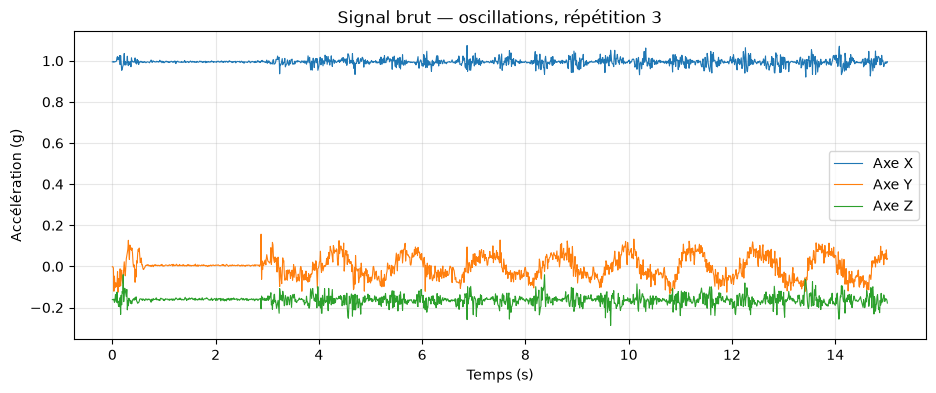

In [50]:
SITUATION  = "oscillations"   # "immobile", "inclinaison", "rotation" ou "oscillations"
REPETITION = 3
         # 1, 2 ou 3

df, info = acquerir(SITUATION, REPETITION)
controler(df, info)

## 7. Avancement des 12 enregistrements

In [ ]:
etat = pd.DataFrame(
    {f"rep{r}": ["✅" if (DOSSIER_RAW / f"{s}_rep{r}.csv").exists() else "⬜" for s in SITUATIONS]
     for r in REPETITIONS},
    index=SITUATIONS)
display(etat)
if JOURNAL_ACQ.exists():
    display(pd.read_csv(JOURNAL_ACQ))